In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from shapely.geometry import box

GIS = Path("../../data/algemeen/gis")
CRS = "EPSG:31370"                
GEO = (".shp", ".gpkg", ".geojson")

UITVOER = Path("../../fig/H2")
UITVOER.mkdir(parents=True, exist_ok=True)


def laad(map_, wat, jaar):
    """Bestandsnaam wat_jaar, waarbij jaar ook een periode kan zijn."""
    treffers = [p for p in sorted((GIS / map_).glob(f"{wat}_{jaar}*"))
                if p.suffix.lower() in GEO]
    if not treffers:
        raise FileNotFoundError(f"{wat}_{jaar} niet gevonden in {GIS / map_}")
    return gpd.read_file(treffers[0]).to_crs(CRS)


for map_ in ("wijken", "bebouwing"):
    print(map_ + ":", ", ".join(sorted(p.stem for p in (GIS / map_).glob("*")
                                       if p.suffix.lower() in GEO)))

wijken: ._wijken_1874-1886, ._wijken_1886-1901, ._wijken_1901-1920, ._wijken_1921-1944, wijken_1874-1886, wijken_1886-1901, wijken_1901-1920, wijken_1921-1944
bebouwing: ._bebouwing_1886, ._bebouwing_1908, ._vesting_1886, ._vesting_1908, ._water_1886, ._water_1908, bebouwing_1886, bebouwing_1908, vesting_1886, vesting_1908, water_1886, water_1908


In [2]:
# 1874–1886 en 1886–1901 zijn identiek en worden samen getoond
PERIODES = {1874: "1874–1900",
            1901: "1901–1920",
            1921: "1921–1940"}


def vind_nr_col(gdf, voorkeur=None):
    """Geeft de kolomnaam met het wijknummer terug."""
    if voorkeur and voorkeur in gdf.columns:
        return voorkeur
    for k in ["SectionNr", "Section_Nr", "SECTIONNR", "wijk", "WIJK", "wijknr",
              "WIJKNR", "nr", "NR", "nummer", "NUMMER", "id", "ID"]:
        if k in gdf.columns:
            return k
    raise KeyError(f"Geen wijkkolom gevonden. Kolommen: {list(gdf.columns)}")


def laad_wijken(startjaar):
    gdf = laad("wijken", "wijken", startjaar)
    gdf["wijk"] = pd.to_numeric(gdf[vind_nr_col(gdf)], errors="coerce").astype("Int64")
    gdf["centroid"] = gdf.geometry.representative_point()
    return gdf


wijken = {}
for startjaar, label in PERIODES.items():
    wijken[startjaar] = laad_wijken(startjaar)
    print(f"{label}: {len(wijken[startjaar]):>2} wijken")

# controle: zijn 1874–1886 en 1886–1901 werkelijk identiek?
opp_74 = wijken[1874].set_index("wijk").geometry.area
opp_86 = laad_wijken(1886).set_index("wijk").geometry.area
print(f"\nzelfde wijknummers: {sorted(opp_74.index) == sorted(opp_86.index)}"
      f" | max. verschil in oppervlakte: {(opp_74 - opp_86).abs().max():,.0f} m²")

1874–1900:  9 wijken
1901–1920: 10 wijken
1921–1940: 12 wijken



zelfde wijknummers: True | max. verschil in oppervlakte: 1,778 m²


In [3]:
def selecteer_water(water, min_ha=3.0):
    """Houdt alle waterlichamen boven min_ha (Schelde, dokken)."""
    w = water.explode(index_parts=False).reset_index(drop=True)
    return w[w.geometry.area / 1e4 >= min_ha]

ACHTERGROND = {
    1874: {"bebouwing": 1886, "water": 1886, "omwalling": 1886},
    1901: {"bebouwing": 1908, "water": 1908, "omwalling": 1886},
    1921: {"bebouwing": 1908, "water": 1908, "omwalling": 1908},
}

achtergrond = {}
for j, cfg in ACHTERGROND.items():
    lagen = {"bebouwing": laad("bebouwing", "bebouwing", cfg["bebouwing"]),
             "water": selecteer_water(laad("bebouwing", "water", cfg["water"])),
             "omwalling": laad("bebouwing", "vesting", cfg["omwalling"])}
    achtergrond[j] = lagen
    print(f"{PERIODES[j]}: " + ", ".join(
        f"{naam} {len(laag)} objecten" for naam, laag in lagen.items()))

1874–1900: bebouwing 1745 objecten, water 19 objecten, omwalling 16 objecten
1901–1920: bebouwing 2090 objecten, water 17 objecten, omwalling 16 objecten
1921–1940: bebouwing 2090 objecten, water 17 objecten, omwalling 41 objecten


In [4]:
TEKST_BREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Libertinus Serif"],
    "font.size": CORPS,
    "axes.titlesize": CORPS,
    "figure.facecolor": "white",
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.01,
})

# maximale hoogte van een afbeelding (tekstblok min ruimte voor het bijschrift)
TEKST_HOOGTE = 185 / 25.4

KLEUR_STAD = "#c8c8c8"
KLEUR_WATER = "#c8d8e8"
KLEUR_GRENS = "#1a1a1a"
KLEUR_LABEL = "#1a1a1a"

LIJN_GRENS = 1.1
LIJN_OMWALLING = 1.0
CORPS_LABEL = CORPS_KLEIN
CORPS_SCHAAL = CORPS_KLEIN


def meter_in_asfractie(ax, lengte_m):
    """Hoeveel van de asbreedte beslaat lengte_m? Nodig door aspect='equal'."""
    inv = ax.transAxes.inverted()
    p0 = inv.transform(ax.transData.transform((0, 0)))
    p1 = inv.transform(ax.transData.transform((lengte_m, 0)))
    return p1[0] - p0[0]


def schaalbalk(ax, lengte_m=2000, links=0.02, onder=0.06):
    lengte = meter_in_asfractie(ax, lengte_m)
    ax.plot([links, links + lengte], [onder, onder], transform=ax.transAxes,
            color=KLEUR_GRENS, linewidth=3.0, solid_capstyle="butt",
            clip_on=False, zorder=8)
    ax.text(links + lengte / 2, onder + 0.015, f"{lengte_m / 1000:.0f} km",
            transform=ax.transAxes, ha="center", va="bottom",
            fontsize=CORPS_SCHAAL, color=KLEUR_GRENS, clip_on=False, zorder=8)


def noordpijl(ax, links=0.02, onder=0.14, hoogte=0.07):
    ax.annotate("", xy=(links, onder + hoogte), xytext=(links, onder),
                xycoords=ax.transAxes, textcoords=ax.transAxes,
                annotation_clip=False, zorder=8,
                arrowprops=dict(arrowstyle="-|>", color=KLEUR_GRENS,
                                linewidth=1.2, mutation_scale=12))
    ax.text(links, onder + hoogte + 0.012, "N", transform=ax.transAxes,
            ha="center", va="bottom", fontsize=CORPS_SCHAAL,
            color=KLEUR_GRENS, clip_on=False, zorder=8)

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [5]:
lagen_mee = [wijken[j].geometry for j in PERIODES]
for j in PERIODES:
    lagen_mee += [achtergrond[j][n].geometry for n in ("bebouwing", "omwalling")]

alles = gpd.GeoSeries(pd.concat(lagen_mee), crs=CRS)
xmin, ymin, xmax, ymax = alles.total_bounds
marge = 0.02 * max(xmax - xmin, ymax - ymin)
xmin, xmax = xmin - marge, xmax + marge
ymin, ymax = ymin - marge, ymax + marge
print(f"{(xmax - xmin) / 1000:.1f} × {(ymax - ymin) / 1000:.1f} km")

6.8 × 9.8 km


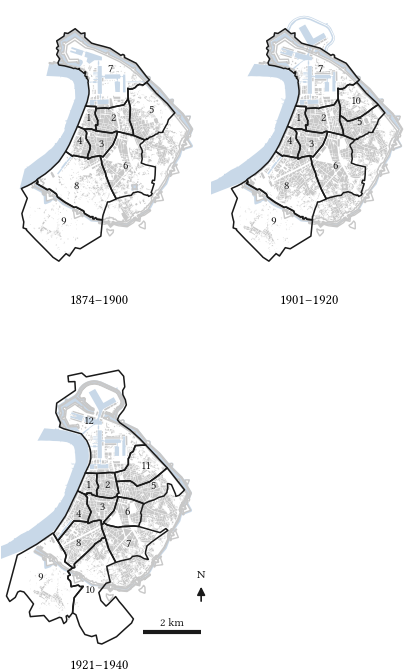

figuur na bijsnijden: 103 × 170 mm (tekstblok 136 × 210 mm)


In [6]:
from matplotlib.gridspec import GridSpec

TITELRUIMTE = 0.55              # inch voor twee rijen bijschriften

kaart_verhouding = (ymax - ymin) / (xmax - xmin)
breedte = min(TEKST_BREEDTE, (TEKST_HOOGTE - TITELRUIMTE) / kaart_verhouding)
hoogte = breedte * kaart_verhouding + TITELRUIMTE

fig = plt.figure(figsize=(breedte, hoogte))
gs = GridSpec(2, 2, figure=fig, wspace=0.06, hspace=0.28,
              left=0.02, right=0.98, top=0.99, bottom=0.02)

vakjes = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]),
          fig.add_subplot(gs[1, 0])]

for ax, (startjaar, label) in zip(vakjes, PERIODES.items()):
    gdf = wijken[startjaar]
    lagen = achtergrond[startjaar]

    lagen["bebouwing"].plot(ax=ax, color=KLEUR_STAD, edgecolor="none",
                            linewidth=0, zorder=1)
    lagen["water"].plot(ax=ax, color=KLEUR_WATER, edgecolor="none",
                        linewidth=0, zorder=2)
    lagen["omwalling"].plot(ax=ax, color="none", edgecolor=KLEUR_STAD,
                            linewidth=LIJN_OMWALLING, zorder=3)
    gdf.plot(ax=ax, facecolor="none", edgecolor=KLEUR_GRENS,
             linewidth=LIJN_GRENS, zorder=4)

    for _, rij in gdf.iterrows():
        if pd.isna(rij["wijk"]):
            continue
        ax.annotate(int(rij["wijk"]), xy=(rij["centroid"].x, rij["centroid"].y),
                    ha="center", va="center", fontsize=CORPS_LABEL,
                    color=KLEUR_LABEL, zorder=5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.text(0.5, -0.03, label, transform=ax.transAxes,
            ha="center", va="top", fontsize=mpl.rcParams["axes.titlesize"])

fig.canvas.draw()               # aspect toepassen vóór de omrekening naar asfractie
LINKS_BALK = 0.72
schaalbalk(vakjes[-1], links=LINKS_BALK, onder=0.06)
noordpijl(vakjes[-1],
          links=LINKS_BALK + meter_in_asfractie(vakjes[-1], 2000),
          onder=0.16)

fig.savefig(UITVOER / "2.1_wijkgrenzen_1874-1944.png", dpi=300)
plt.show()

bbox = fig.get_tightbbox(fig.canvas.get_renderer())
print(f"figuur na bijsnijden: {bbox.width * 25.4:.0f} × {bbox.height * 25.4:.0f} mm "
      f"(tekstblok 136 × 210 mm)")